In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_excel("ApexPlanet.xlsx")
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,27906.16,139530.80
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,37491.06,299928.48
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90


# Dataset Description

The dataset contains the following 12 columns:

| Column Name | Data Type | Description |
|---|---|---|
| Order_ID | String | Unique identification number for each order |
| Order_Date | Object | Date when the order was placed |
| Customer_ID | String | Unique identification number for each customer |
| Customer_Name | String | Name of the customer |
| Age | Float | Age of the customer |
| Gender | String | Gender of the customer |
| City | String | Customer's city |
| Product | String | Name of the purchased product |
| Category | String | Product category |
| Quantity | Integer | Number of units purchased |
| Unit_Price | Float | Price of one product unit |
| Total_Sales | Float | Total sales amount generated |

# Data Cleaning and Quality Checking

In [3]:
df.columns

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Age',
       'Gender', 'City', 'Product', 'Category', 'Quantity', 'Unit_Price',
       'Total_Sales'],
      dtype='object')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       1000 non-null   object 
 1   Order_Date     1000 non-null   object 
 2   Customer_ID    1000 non-null   object 
 3   Customer_Name  1000 non-null   object 
 4   Age            980 non-null    float64
 5   Gender         1000 non-null   object 
 6   City           987 non-null    object 
 7   Product        1000 non-null   object 
 8   Category       1000 non-null   object 
 9   Quantity       1000 non-null   int64  
 10  Unit_Price     1000 non-null   float64
 11  Total_Sales    1000 non-null   float64
dtypes: float64(3), int64(1), object(8)
memory usage: 93.9+ KB


In [5]:
# Convert Order_Date to datetime
df['Order_Date'] = pd.to_datetime(df['Order_Date'])

# Convert Age to integer
df['Age'] = df['Age'].astype('Int64')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order_ID       1000 non-null   object        
 1   Order_Date     1000 non-null   datetime64[ns]
 2   Customer_ID    1000 non-null   object        
 3   Customer_Name  1000 non-null   object        
 4   Age            980 non-null    Int64         
 5   Gender         1000 non-null   object        
 6   City           987 non-null    object        
 7   Product        1000 non-null   object        
 8   Category       1000 non-null   object        
 9   Quantity       1000 non-null   int64         
 10  Unit_Price     1000 non-null   float64       
 11  Total_Sales    1000 non-null   float64       
dtypes: Int64(1), datetime64[ns](1), float64(2), int64(1), object(7)
memory usage: 94.9+ KB


In [7]:
df['Gender'].unique()

array(['Female', 'Male'], dtype=object)

In [8]:
df['City'].unique()

array(['Bengaluru', 'Kolkata', 'Hyderabad', 'Patna', 'Mumbai', 'Delhi',
       'Gaya', 'Pune', nan], dtype=object)

In [9]:
df['Product'].unique()

array(['Rice', 'Book', 'Mobile', 'Laptop', 'Shoes', 'Chair'], dtype=object)

In [10]:
df['Category'].unique()

array(['Grocery', 'Education', 'Electronics', 'Fashion', 'Furniture'],
      dtype=object)

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
len(df)

1000

In [13]:
df.isna().sum()/len(df)*100

Order_ID         0.0
Order_Date       0.0
Customer_ID      0.0
Customer_Name    0.0
Age              2.0
Gender           0.0
City             1.3
Product          0.0
Category         0.0
Quantity         0.0
Unit_Price       0.0
Total_Sales      0.0
dtype: float64

In [14]:
df.describe()

,Order_Date,Age,Quantity,Unit_Price,Total_Sales
count,1000,980.0,1000.000000,1000.000000,1000.000000
mean,2025-07-03 11:19:40.800000,41.360204,5.435000,25486.783410,139399.439650
min,2025-01-01 00:00:00,18.0,1.000000,145.780000,437.340000
25%,2025-03-30 18:00:00,30.0,3.000000,13895.722500,47066.632500
50%,2025-07-01 00:00:00,41.0,5.000000,25398.740000,108594.025000
75%,2025-10-07 06:00:00,54.0,8.000000,37512.382500,203722.882500
max,2026-01-01 00:00:00,65.0,10.000000,49997.530000,493677.500000
std,NaN,13.822597,2.838632,14179.402361,114100.051546


In [15]:
# Calculate mean age
mean_age = df['Age'].mean()

# Fill missing Age values with mean
df['Age'] = df['Age'].fillna(round(mean_age))

# Check missing values
print("Missing Age values:", df['Age'].isnull().sum())

Missing Age values: 0


In [16]:
df.dropna(subset=['City'], inplace=True)

In [17]:
df.isna().sum()/len(df)*100

Order_ID         0.0
Order_Date       0.0
Customer_ID      0.0
Customer_Name    0.0
Age              0.0
Gender           0.0
City             0.0
Product          0.0
Category         0.0
Quantity         0.0
Unit_Price       0.0
Total_Sales      0.0
dtype: float64

In [18]:
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,ORD100002,2025-02-25,CUST5529,Customer_227,30,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39
1,ORD100003,2025-10-14,CUST3127,Customer_182,63,Male,Bengaluru,Book,Education,5,27906.16,139530.80
2,ORD100004,2025-05-13,CUST8887,Customer_487,62,Female,Bengaluru,Book,Education,8,37491.06,299928.48
3,ORD100005,2025-12-02,CUST2515,Customer_470,65,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24
4,ORD100006,2025-11-20,CUST4796,Customer_380,44,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90


In [19]:
df.to_csv('Apex.csv')

# Exploratary Data Analysis

## Univariate Analysis

In [20]:
df.describe()

,Order_Date,Age,Quantity,Unit_Price,Total_Sales
count,987,987.0,987.000000,987.000000,987.000000
mean,2025-07-03 10:59:27.173252352,41.355623,5.440729,25532.357477,139674.591803
min,2025-01-01 00:00:00,18.0,1.000000,145.780000,437.340000
25%,2025-03-30 12:00:00,30.0,3.000000,13951.300000,47540.675000
50%,2025-07-01 00:00:00,41.0,5.000000,25461.320000,109163.280000
75%,2025-10-06 12:00:00,53.0,8.000000,37533.705000,203771.920000
max,2026-01-01 00:00:00,65.0,10.000000,49997.530000,493677.500000
std,NaN,13.725215,2.836892,14157.557070,113608.551871


In [21]:
numerical_cols = [
    'Age',
    'Quantity',
    'Unit_Price',
    'Total_Sales'
]

categorical_cols = [
    'Gender',
    'City',
    'Product',
    'Category'
]

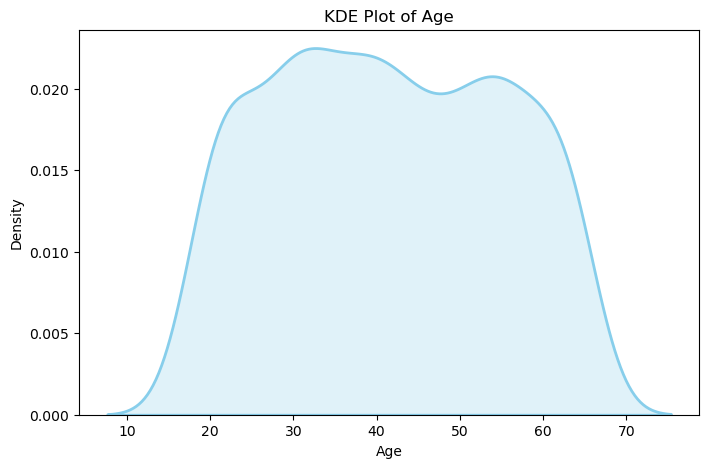

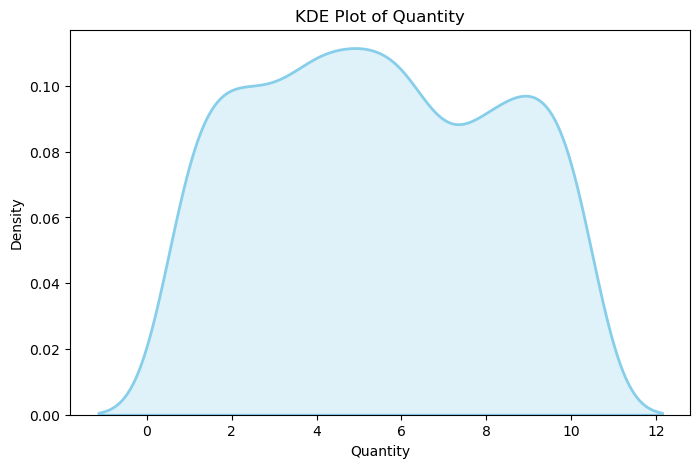

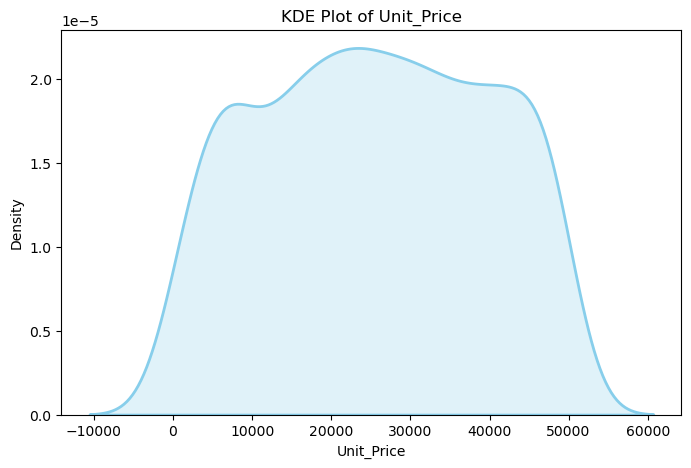

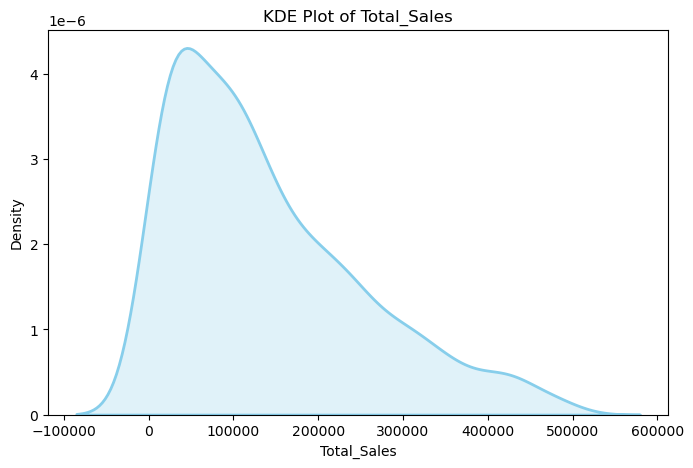

In [22]:
for col in numerical_cols:
    plt.figure(figsize=(8, 5))

    sns.kdeplot(
        data=df,
        x=col,
        fill=True,
        color='skyblue',
        linewidth=2
    )

    plt.title(f'KDE Plot of {col}')
    plt.xlabel(col)
    plt.ylabel('Density')
    plt.show()

In [23]:
df[numerical_cols].skew()

Age            0.041196
Quantity       0.056822
Unit_Price    -0.026871
Total_Sales    0.977586
dtype: Float64

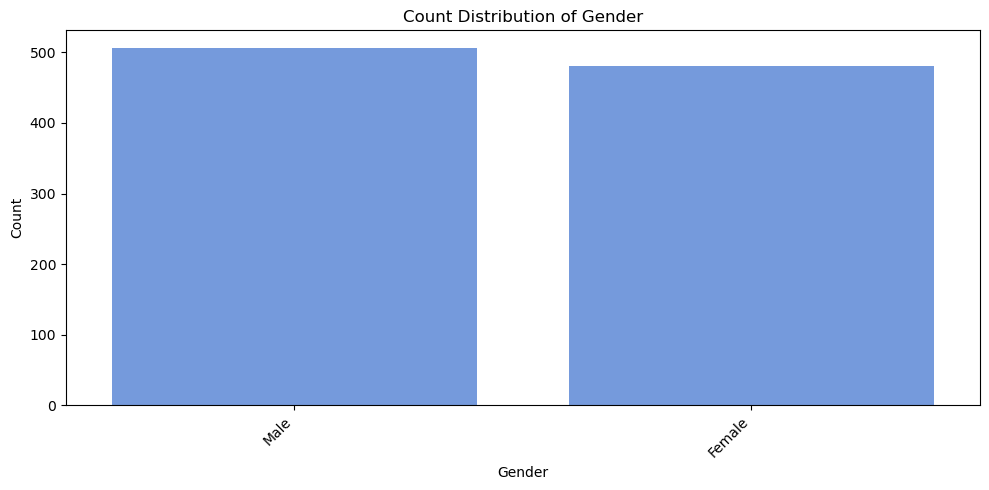

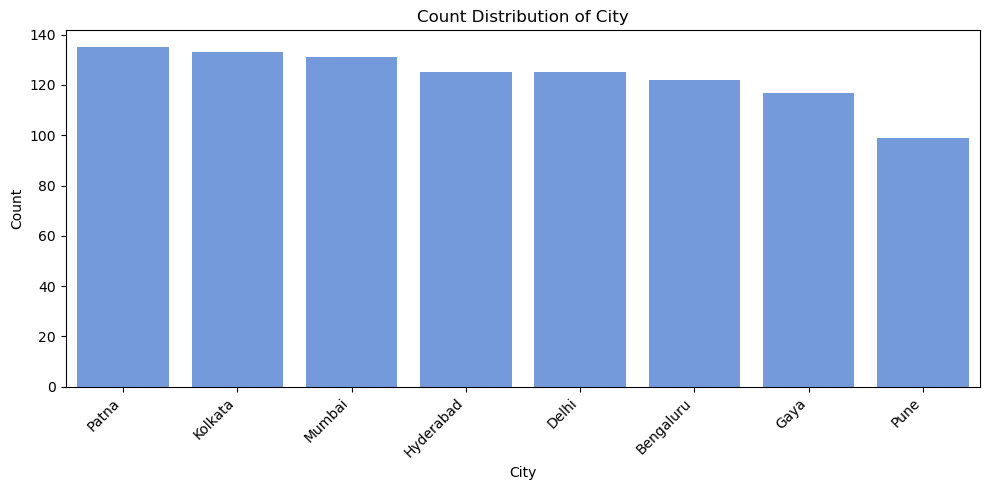

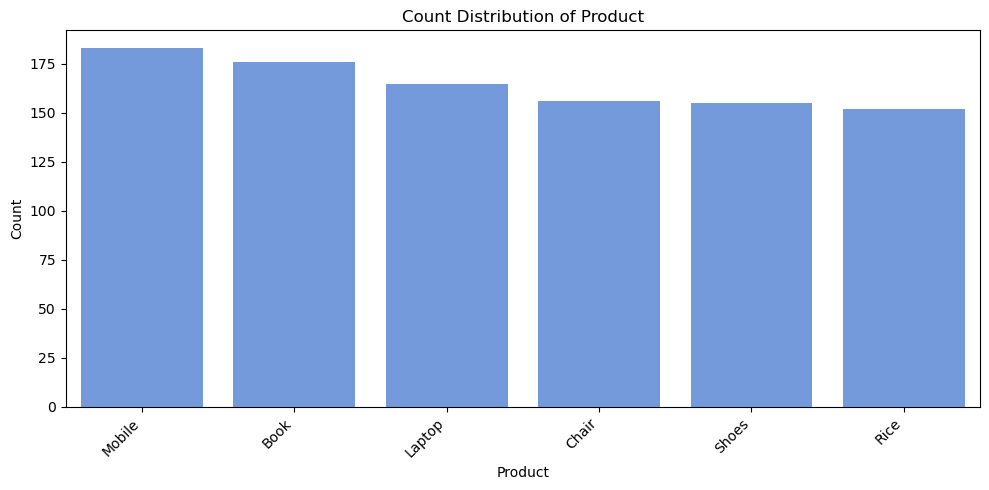

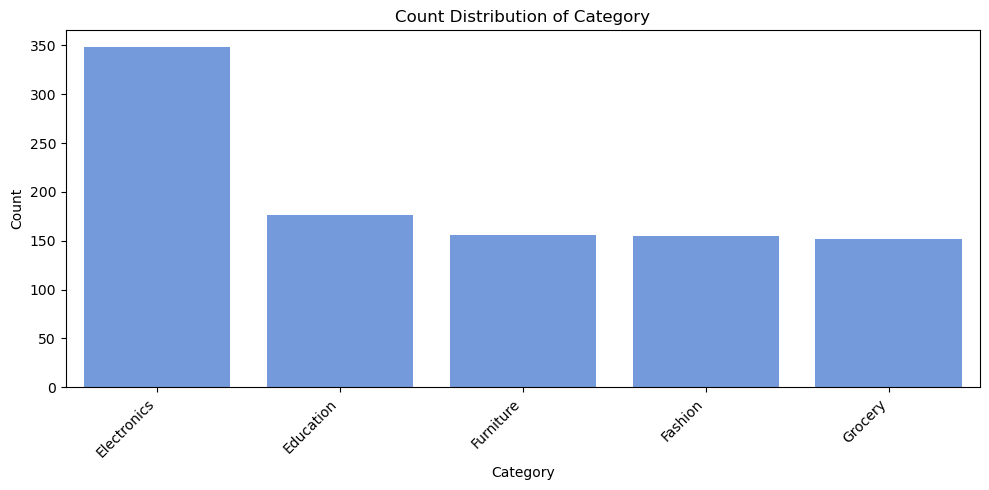

In [24]:
for col in categorical_cols:

    plt.figure(figsize=(10, 5))

    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        x=col,
        order=order,
        color='cornflowerblue'
    )

    plt.title(f'Count Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')

    plt.xticks(rotation=45, ha='right')

    plt.tight_layout()
    plt.show()

## Bivariate Analysis

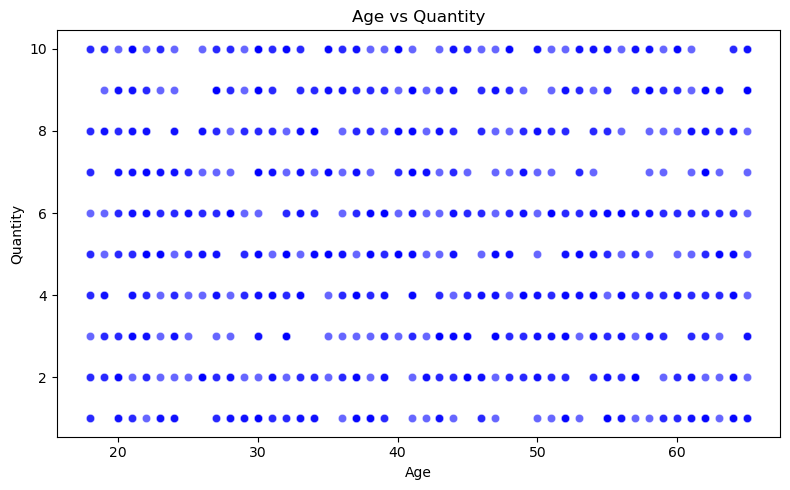

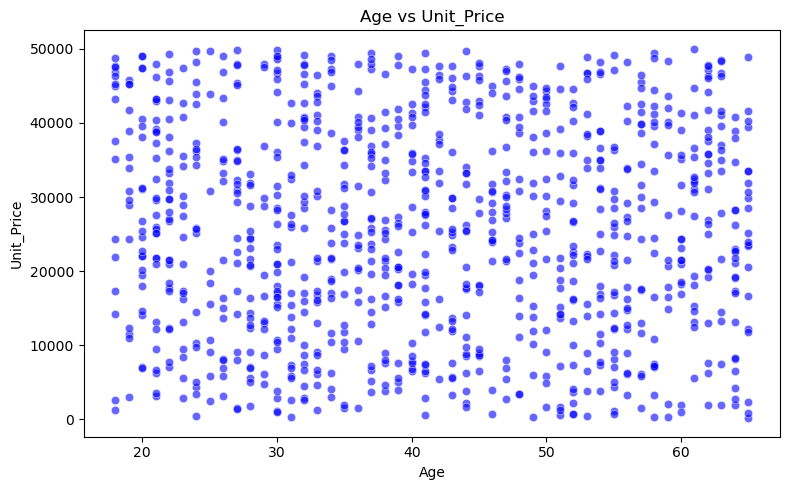

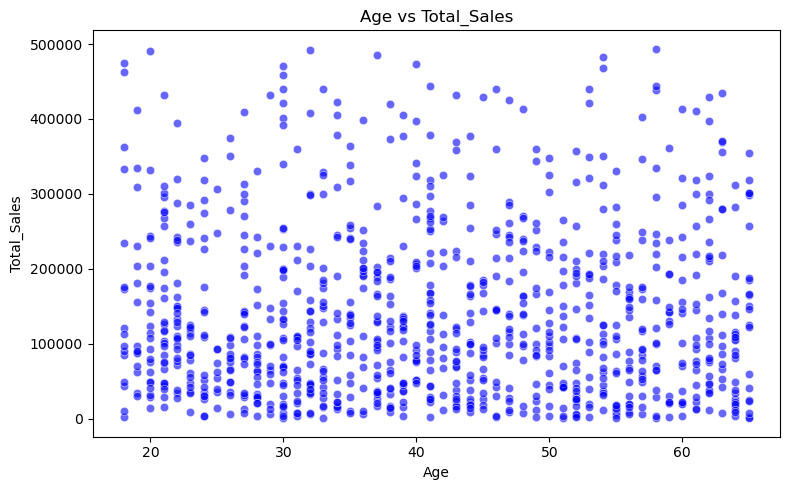

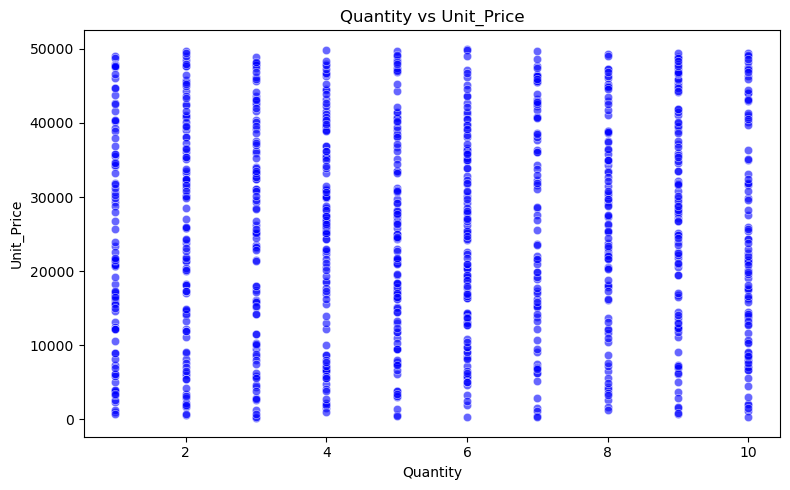

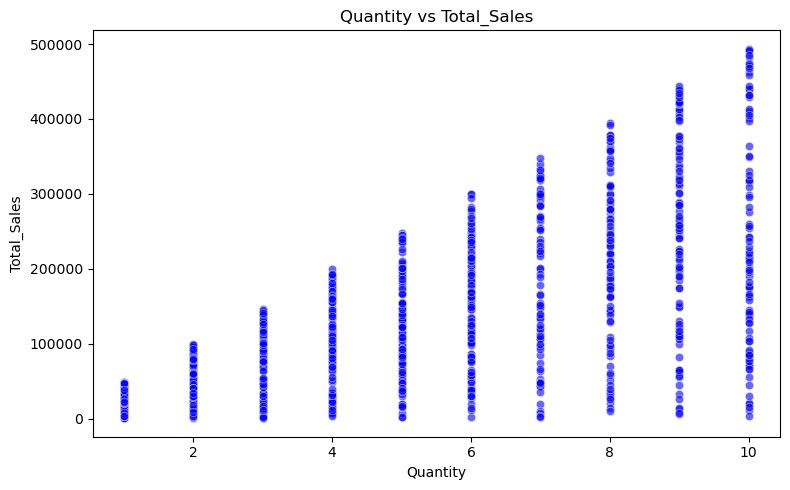

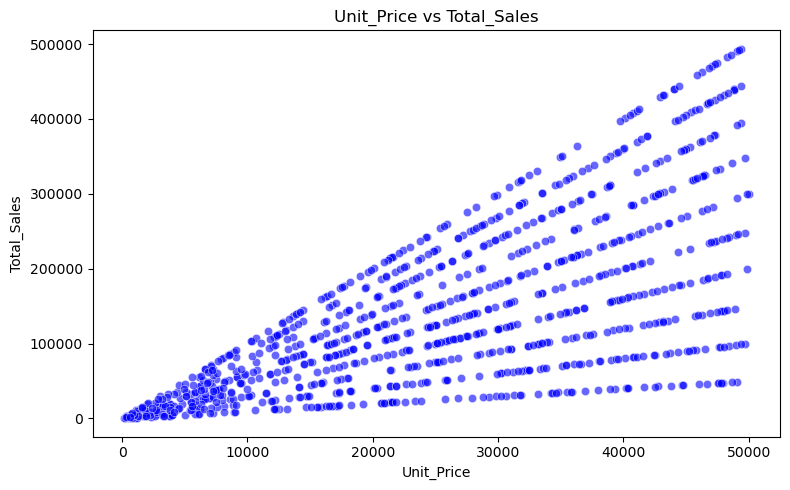

In [25]:
pairs = [
    ('Age', 'Quantity'),
    ('Age', 'Unit_Price'),
    ('Age', 'Total_Sales'),
    ('Quantity', 'Unit_Price'),
    ('Quantity', 'Total_Sales'),
    ('Unit_Price', 'Total_Sales')
]

for x, y in pairs:

    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=df,
        x=x,
        y=y,
        color='blue',
        alpha=0.6
    )

    plt.title(f'{x} vs {y}')
    plt.xlabel(x)
    plt.ylabel(y)

    plt.tight_layout()
    plt.show()

In [26]:
# Gender vs Category
pd.crosstab(df['Gender'], df['Category'])

Category,Education,Electronics,Fashion,Furniture,Grocery
Gender,,,,,
Female,94,156,88,72,71
Male,82,192,67,84,81


In [27]:
pd.crosstab(df['Gender'], df['City'])

City,Bengaluru,Delhi,Gaya,Hyderabad,Kolkata,Mumbai,Patna,Pune
Gender,,,,,,,,
Female,62,64,52,60,65,68,65,45
Male,60,61,65,65,68,63,70,54


In [28]:
pd.crosstab(df['Gender'], df['Product'])

Product,Book,Chair,Laptop,Mobile,Rice,Shoes
Gender,,,,,,
Female,94,72,70,86,71,88
Male,82,84,95,97,81,67


In [29]:
pd.crosstab(df['City'], df['Category'])

Category,Education,Electronics,Fashion,Furniture,Grocery
City,,,,,
Bengaluru,17,37,27,19,22
Delhi,26,45,17,18,19
Gaya,15,38,20,20,24
Hyderabad,34,36,15,20,20
Kolkata,23,60,16,16,18
Mumbai,24,47,18,24,18
Patna,26,45,21,24,19
Pune,11,40,21,15,12


In [30]:
pd.crosstab(df['City'], df['Product'])

Product,Book,Chair,Laptop,Mobile,Rice,Shoes
City,,,,,,
Bengaluru,17,19,18,19,22,27
Delhi,26,18,18,27,19,17
Gaya,15,20,22,16,24,20
Hyderabad,34,20,22,14,20,15
Kolkata,23,16,25,35,18,16
Mumbai,24,24,25,22,18,18
Patna,26,24,16,29,19,21
Pune,11,15,19,21,12,21


In [31]:
pd.crosstab(df['Category'], df['Product'])

Product,Book,Chair,Laptop,Mobile,Rice,Shoes
Category,,,,,,
Education,176,0,0,0,0,0
Electronics,0,0,165,183,0,0
Fashion,0,0,0,0,0,155
Furniture,0,156,0,0,0,0
Grocery,0,0,0,0,152,0


C:\Users\Welcome\AppData\Local\Temp\ipykernel_15668\1470762331.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


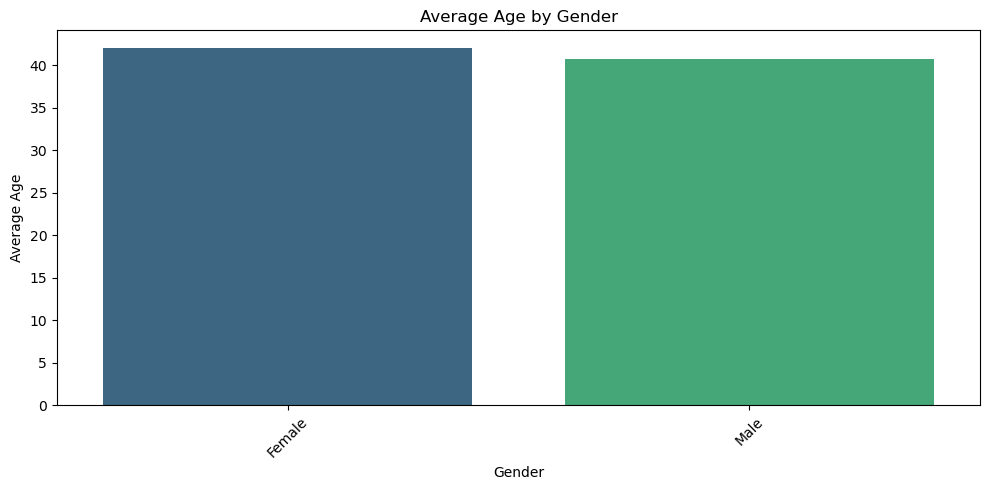

C:\Users\Welcome\AppData\Local\Temp\ipykernel_15668\1470762331.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


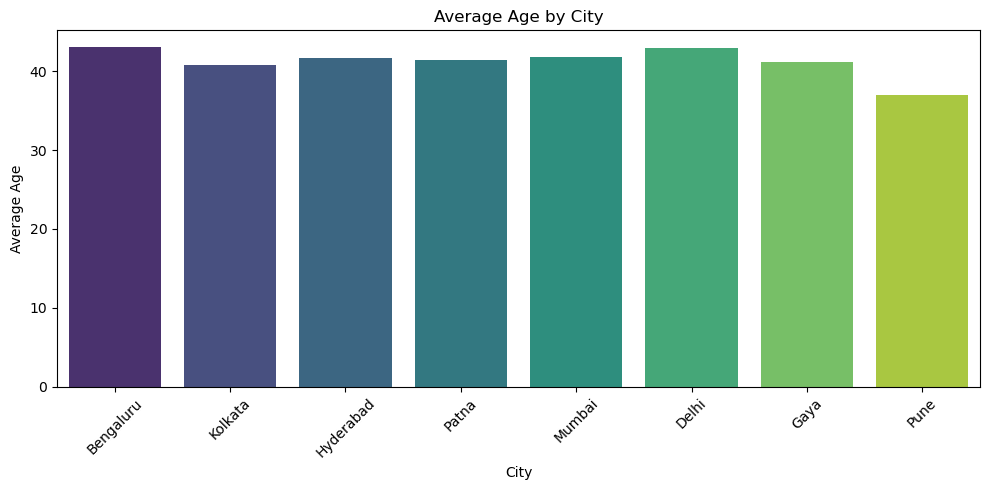

C:\Users\Welcome\AppData\Local\Temp\ipykernel_15668\1470762331.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


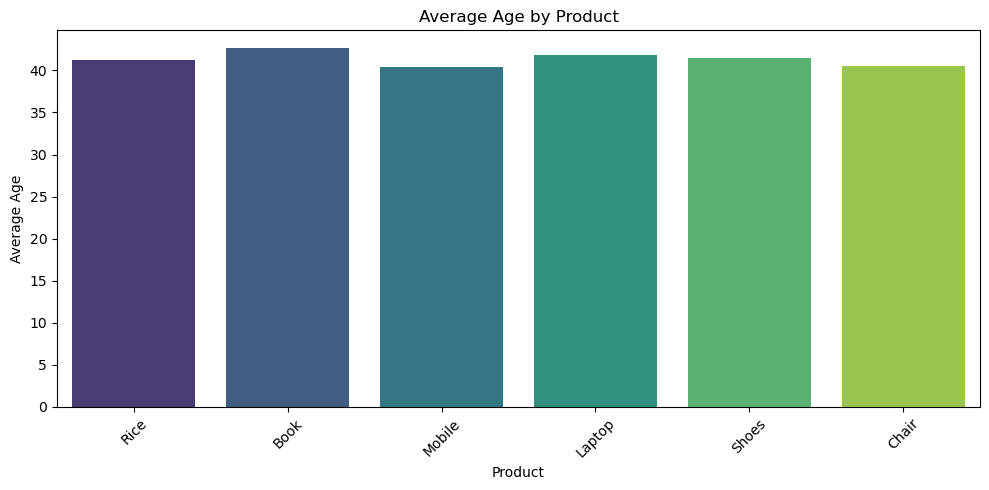

C:\Users\Welcome\AppData\Local\Temp\ipykernel_15668\1470762331.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


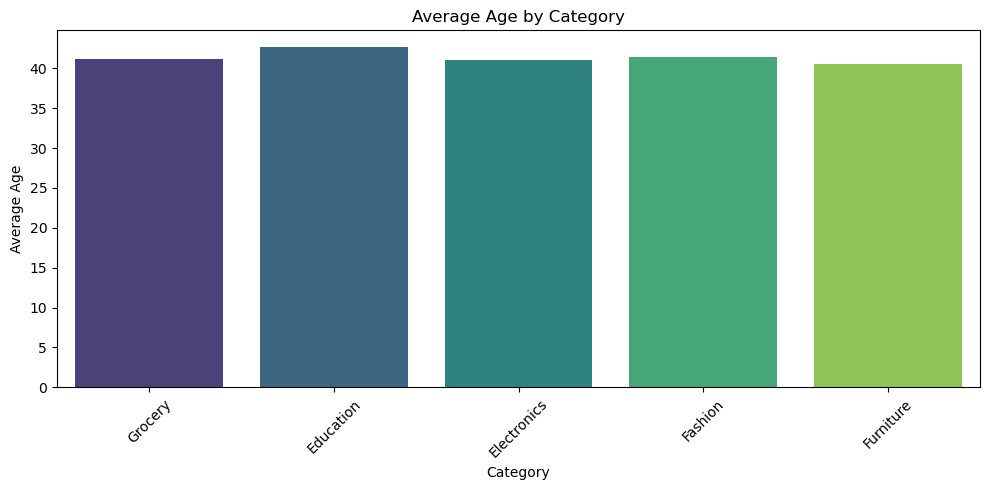

C:\Users\Welcome\AppData\Local\Temp\ipykernel_15668\1470762331.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


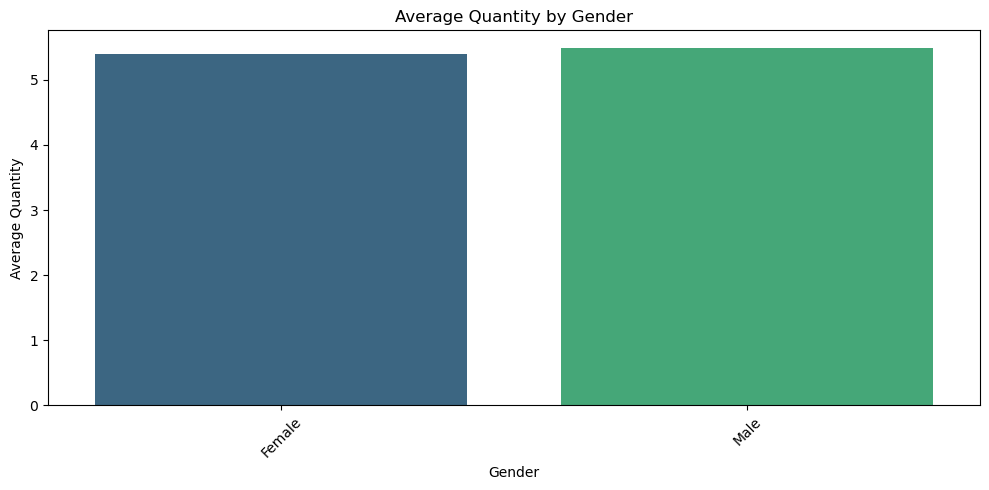

C:\Users\Welcome\AppData\Local\Temp\ipykernel_15668\1470762331.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


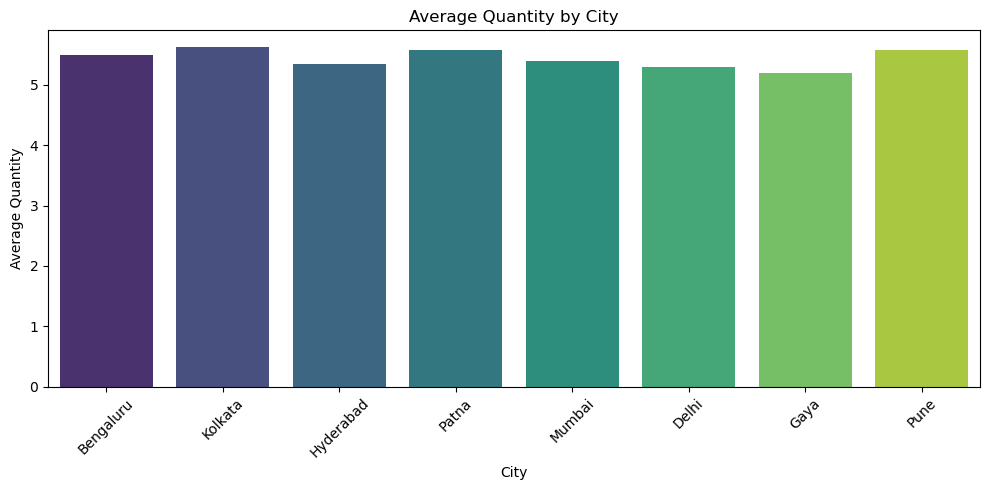

C:\Users\Welcome\AppData\Local\Temp\ipykernel_15668\1470762331.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


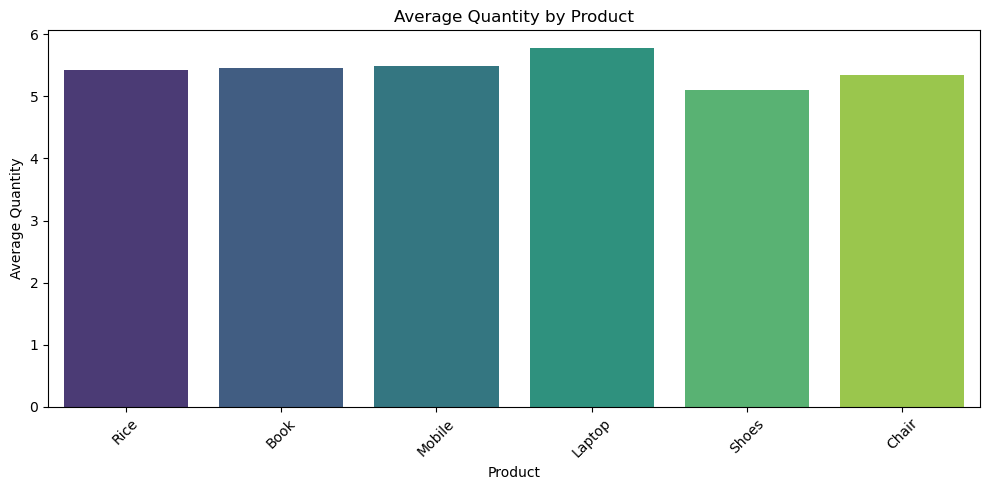

C:\Users\Welcome\AppData\Local\Temp\ipykernel_15668\1470762331.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


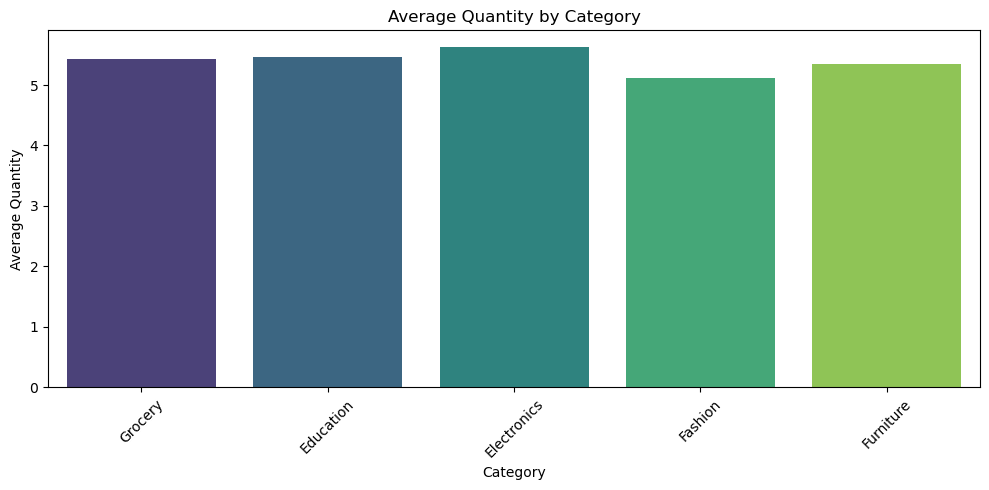

C:\Users\Welcome\AppData\Local\Temp\ipykernel_15668\1470762331.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


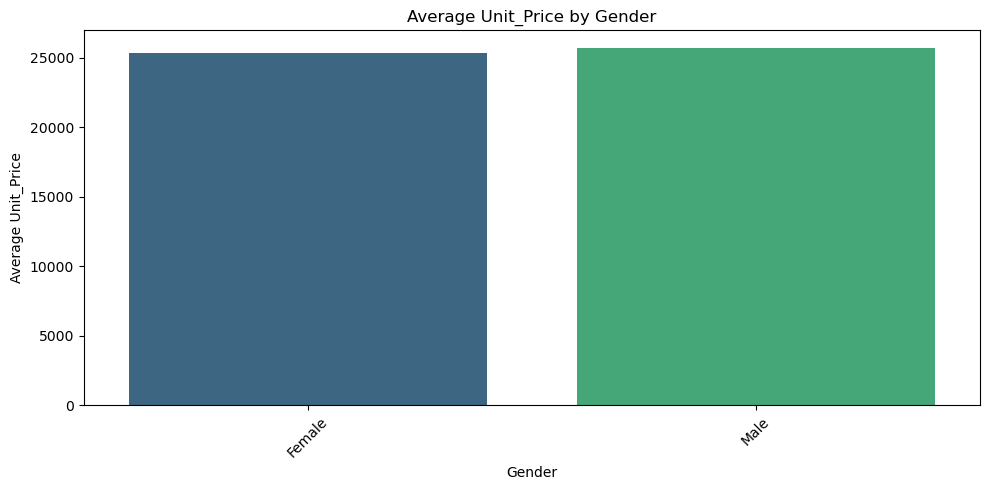

C:\Users\Welcome\AppData\Local\Temp\ipykernel_15668\1470762331.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


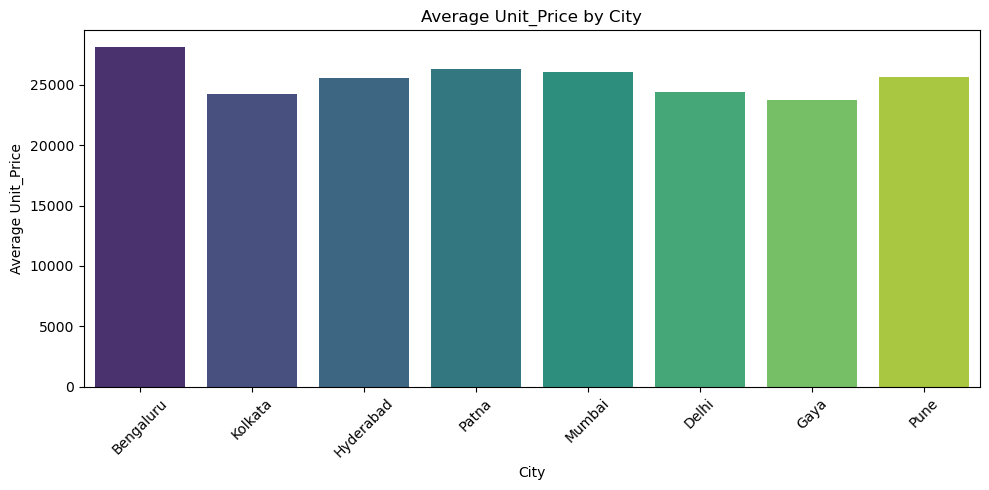

C:\Users\Welcome\AppData\Local\Temp\ipykernel_15668\1470762331.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


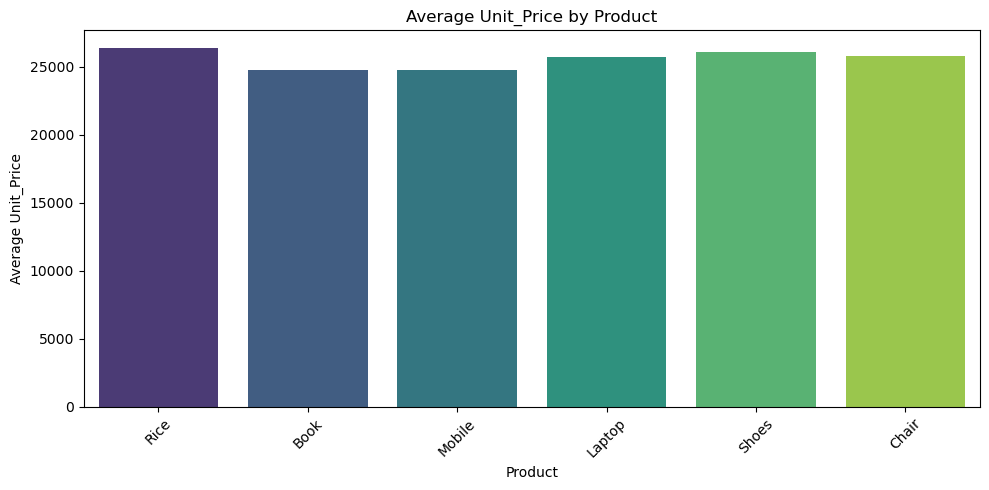

C:\Users\Welcome\AppData\Local\Temp\ipykernel_15668\1470762331.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


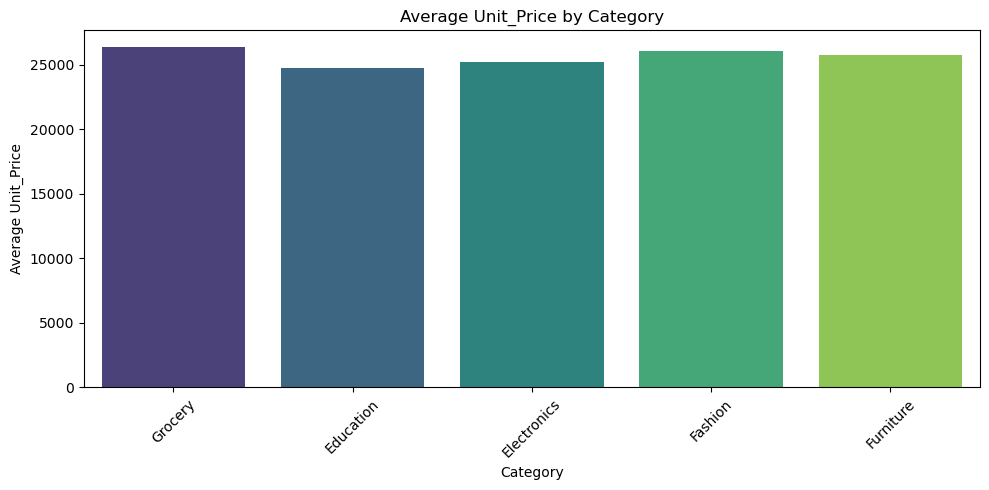

C:\Users\Welcome\AppData\Local\Temp\ipykernel_15668\1470762331.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


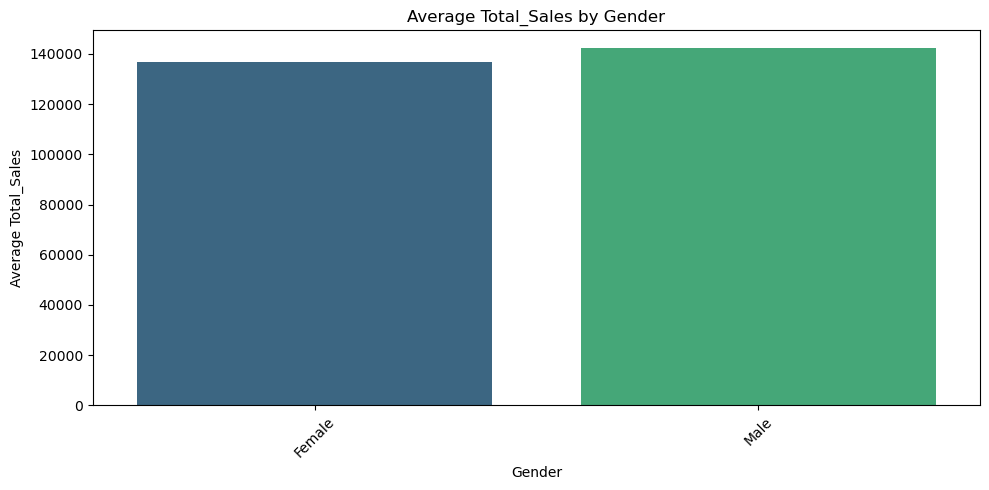

C:\Users\Welcome\AppData\Local\Temp\ipykernel_15668\1470762331.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


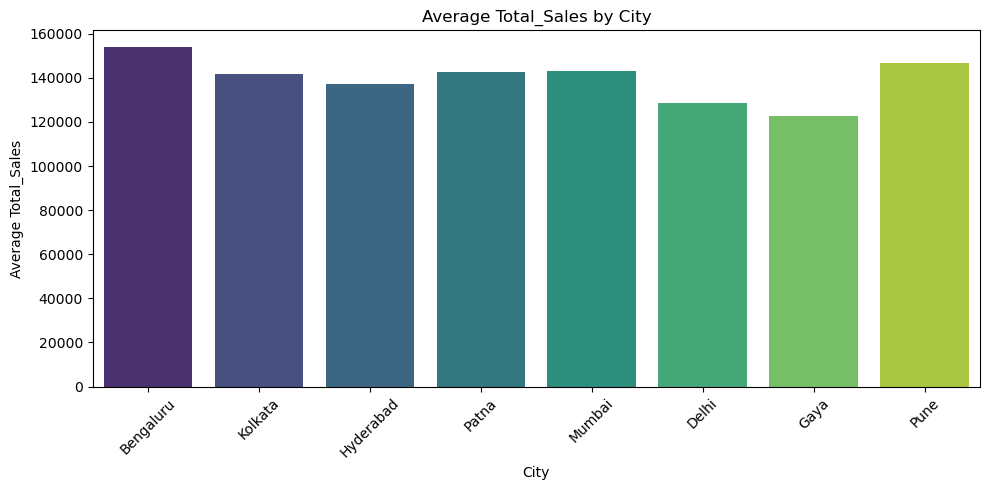

C:\Users\Welcome\AppData\Local\Temp\ipykernel_15668\1470762331.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


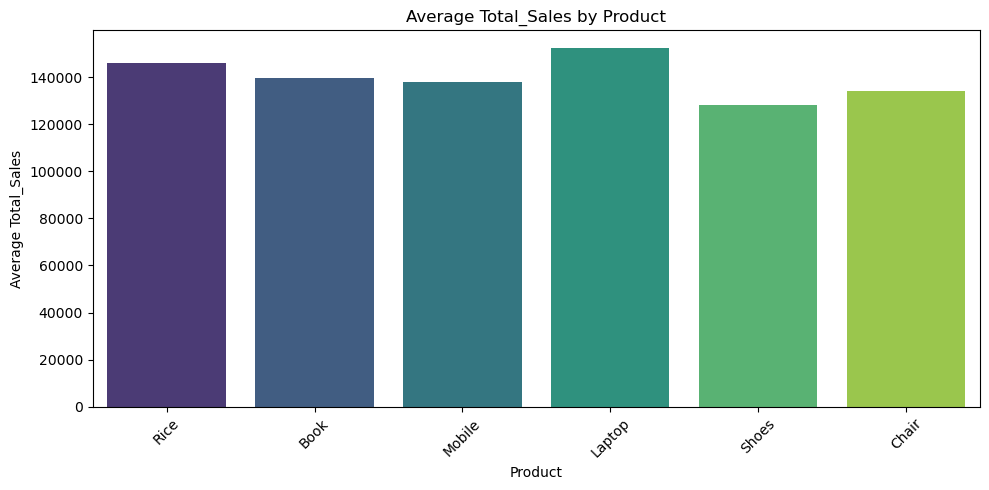

C:\Users\Welcome\AppData\Local\Temp\ipykernel_15668\1470762331.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


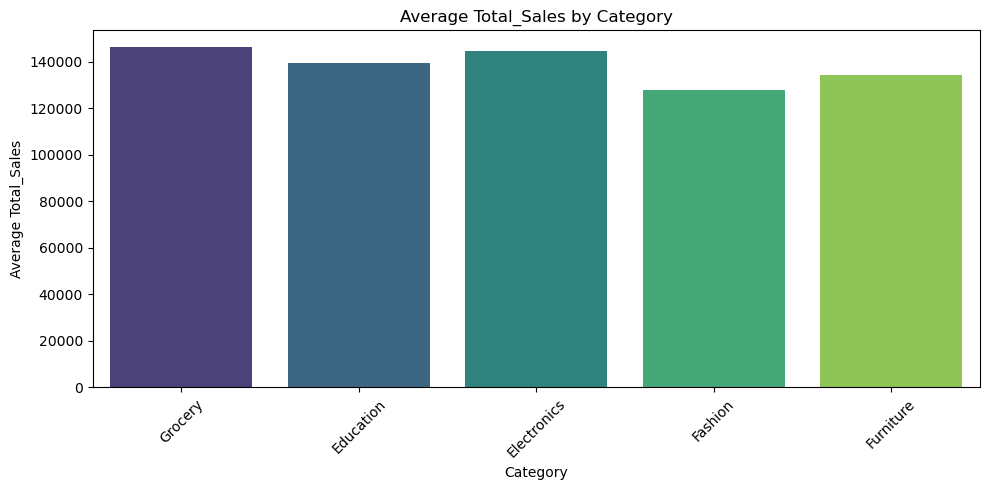

In [32]:
for num_col in numerical_cols:
    for cat_col in categorical_cols:

        plt.figure(figsize=(10, 5))

        sns.barplot(
            data=df,
            x=cat_col,
            y=num_col,
            estimator='mean',
            errorbar=None,
            palette='viridis'
        )

        plt.title(f'Average {num_col} by {cat_col}')
        plt.xlabel(cat_col)
        plt.ylabel(f'Average {num_col}')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

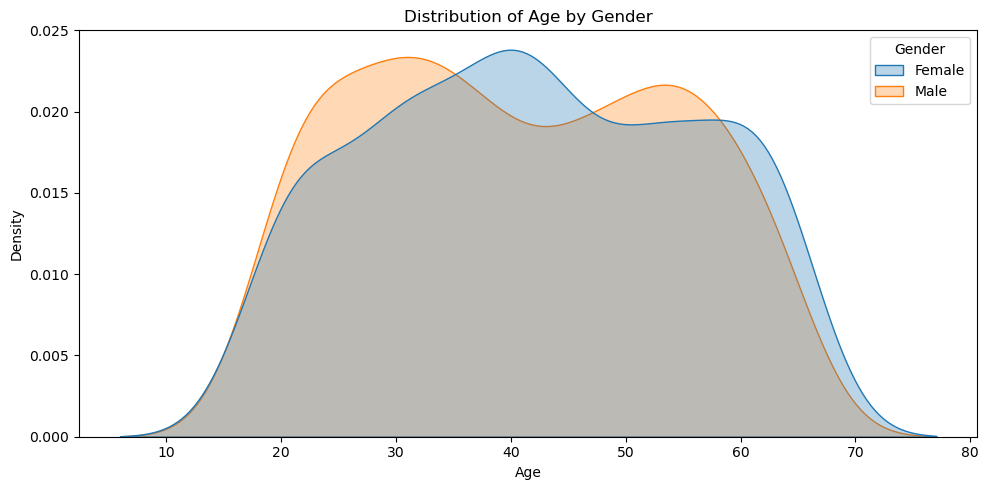

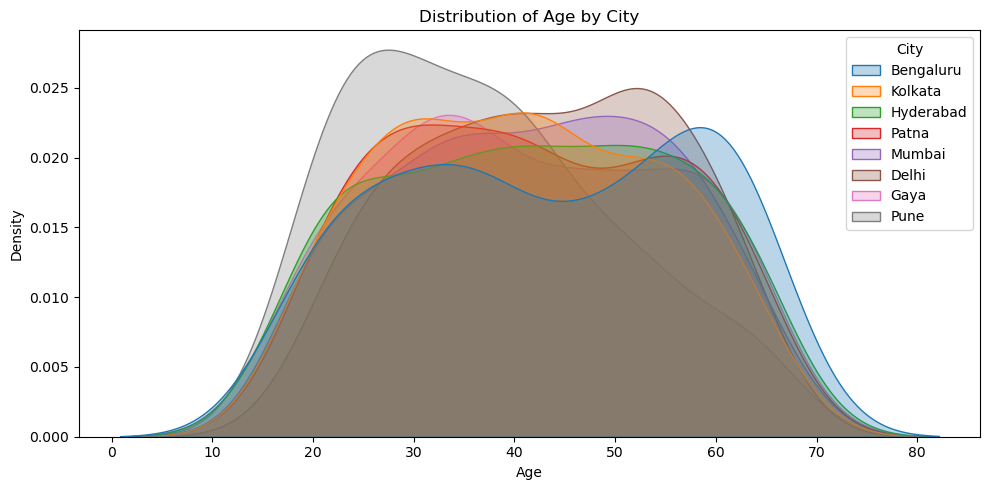

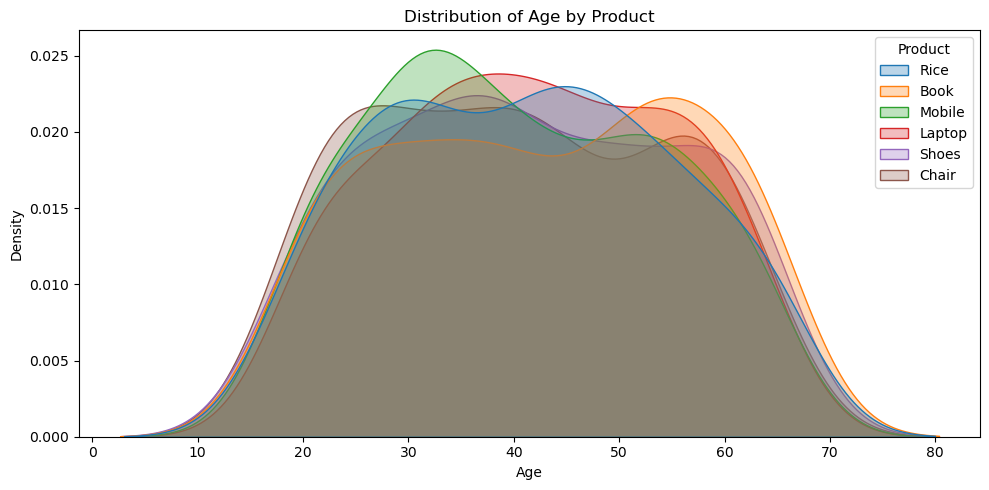

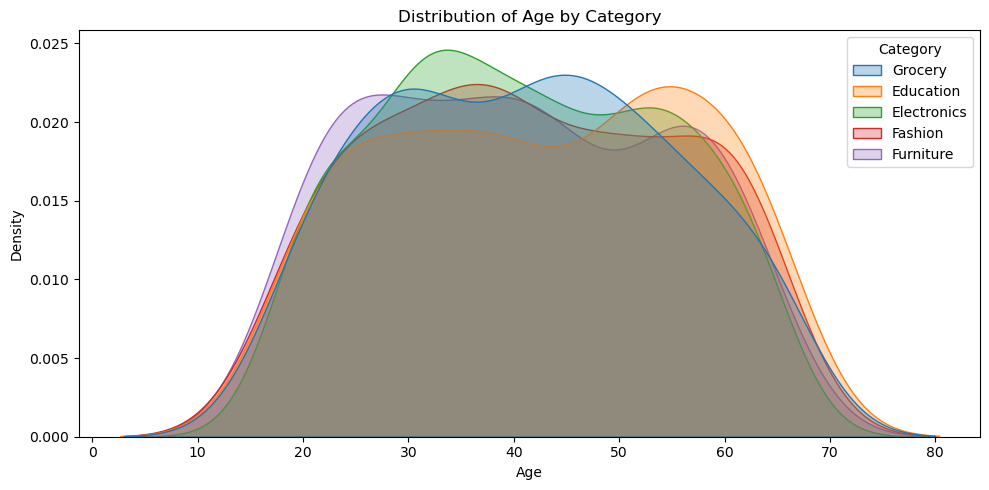

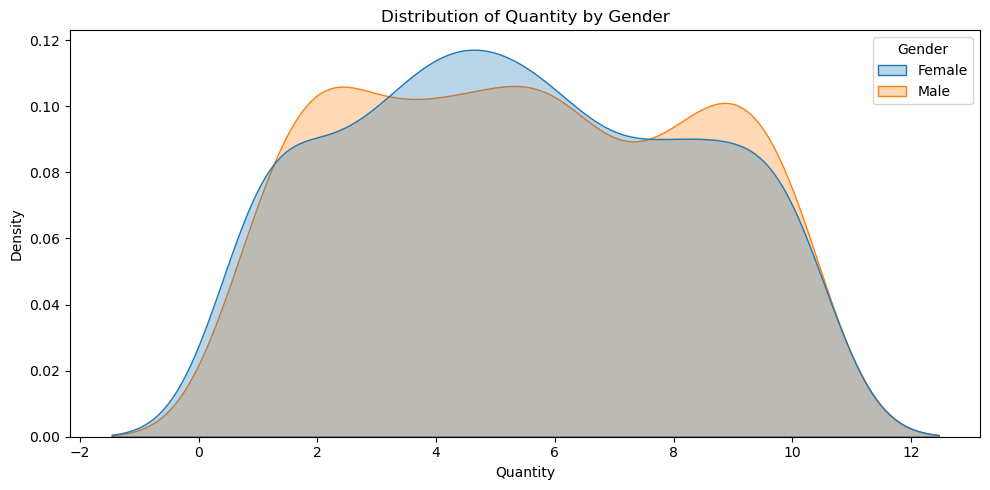

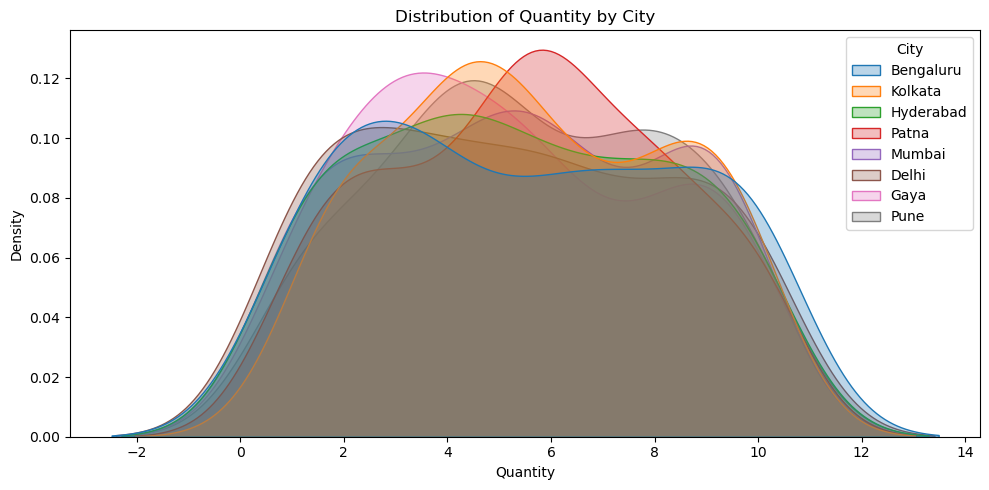

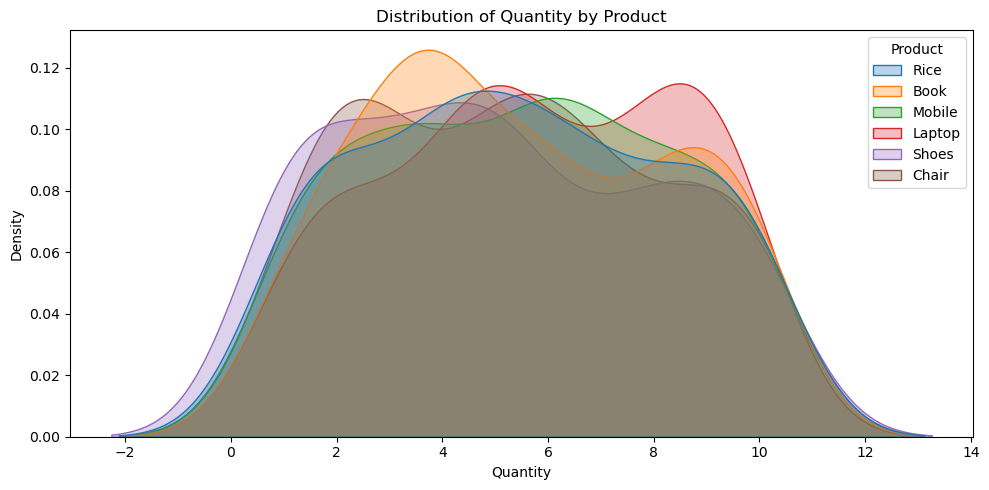

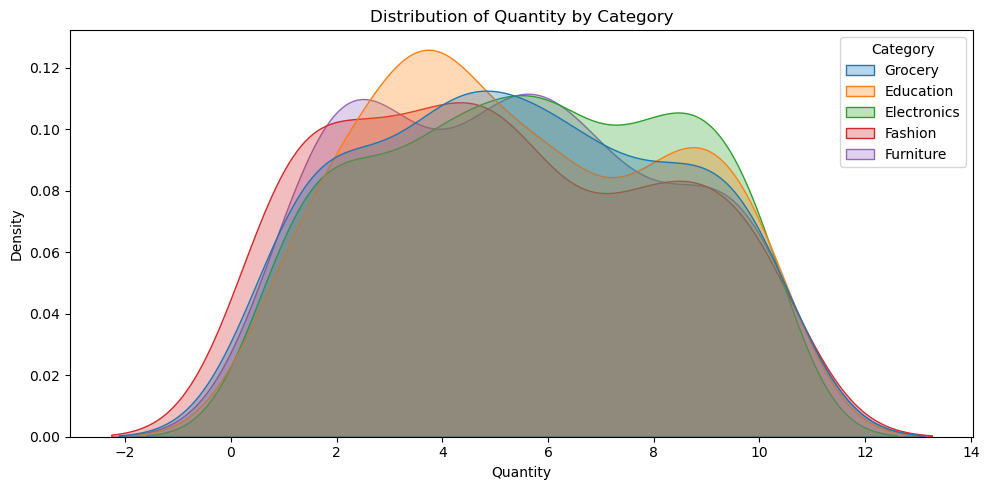

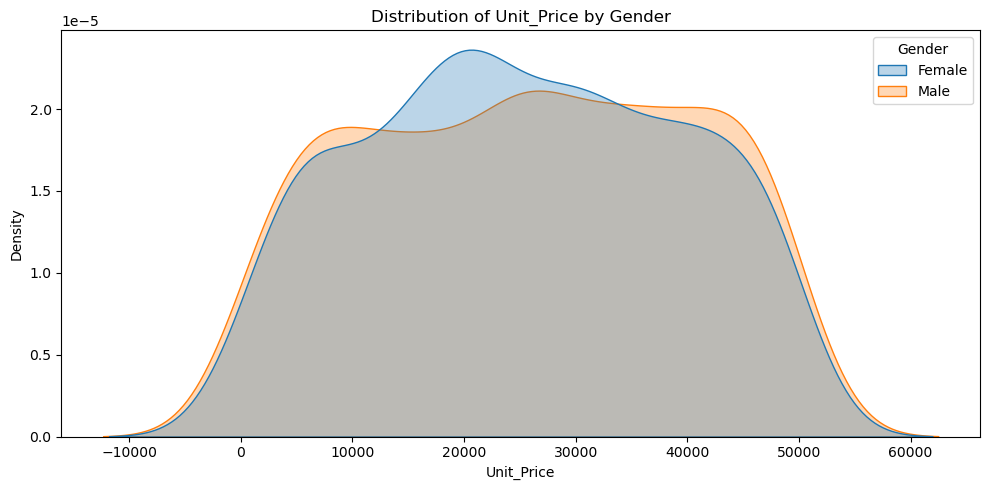

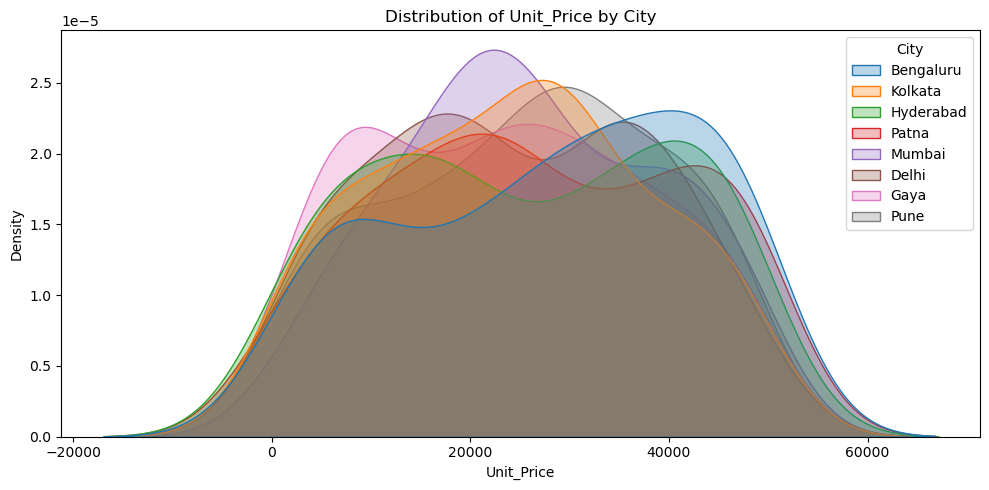

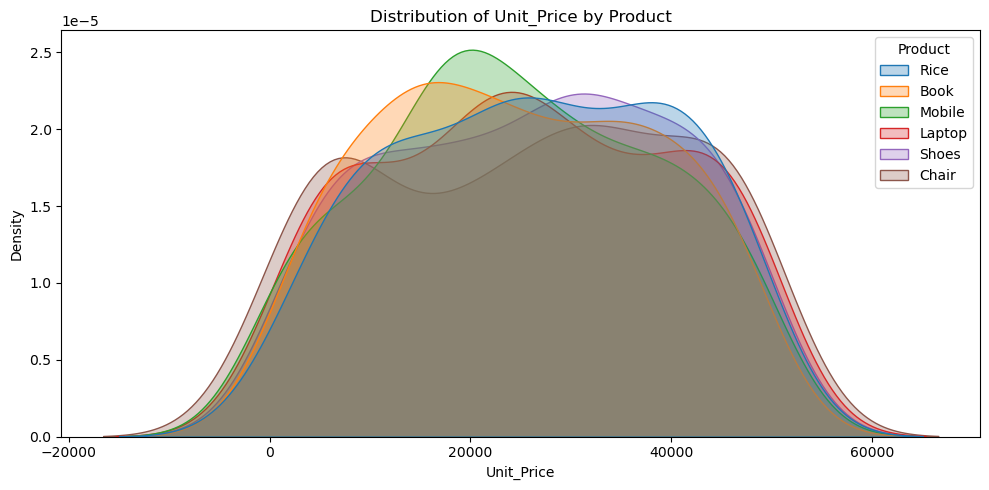

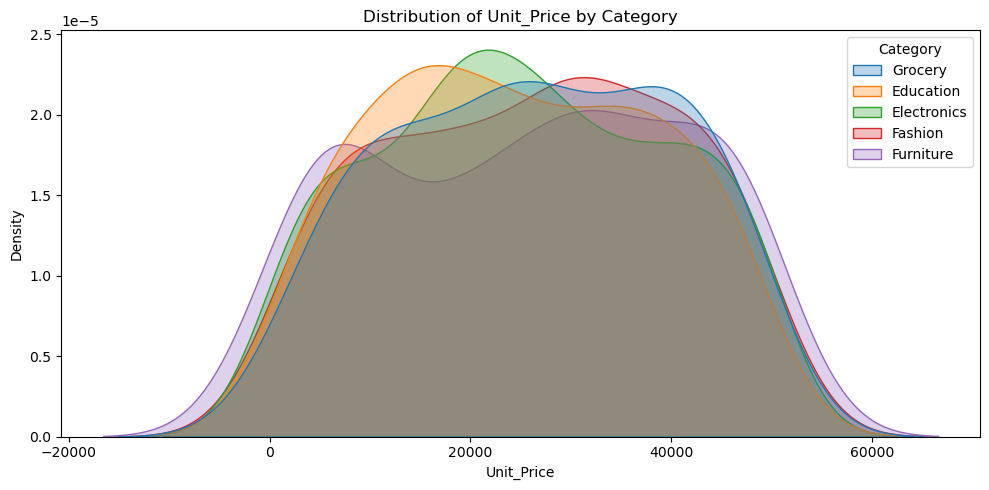

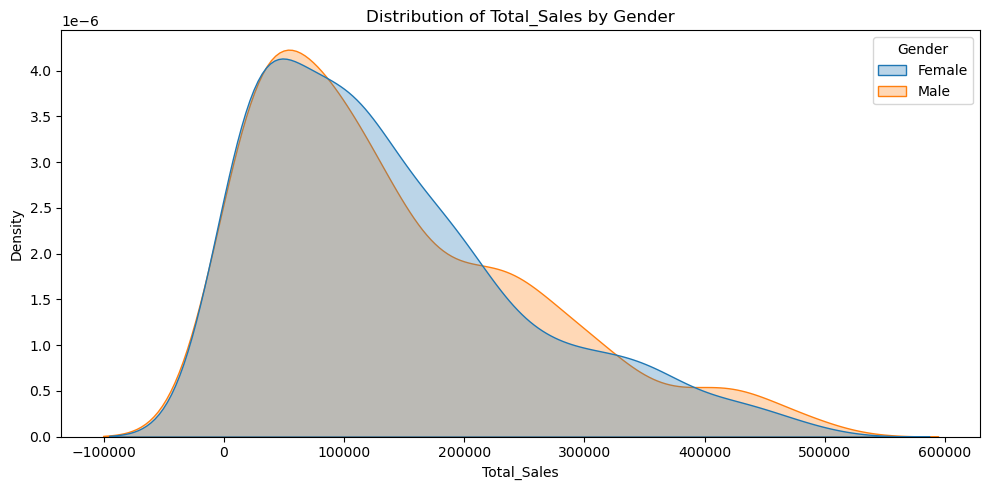

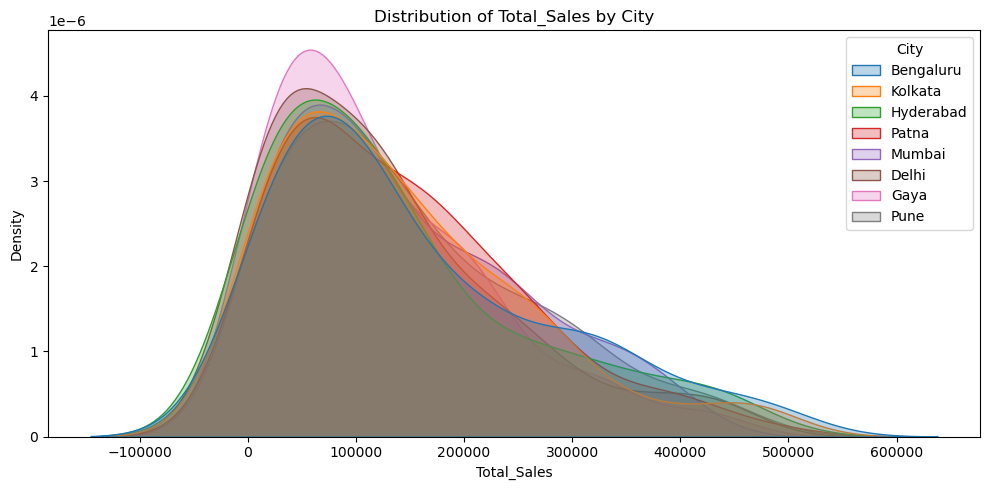

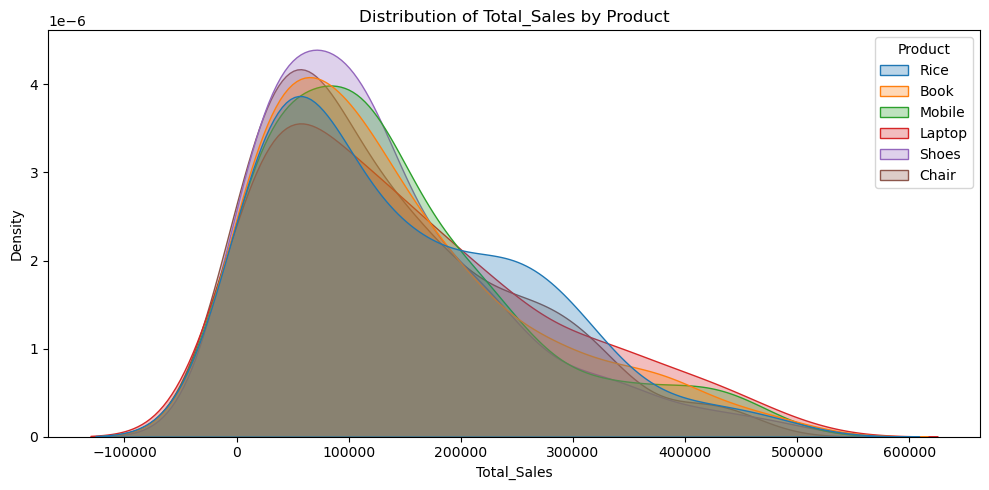

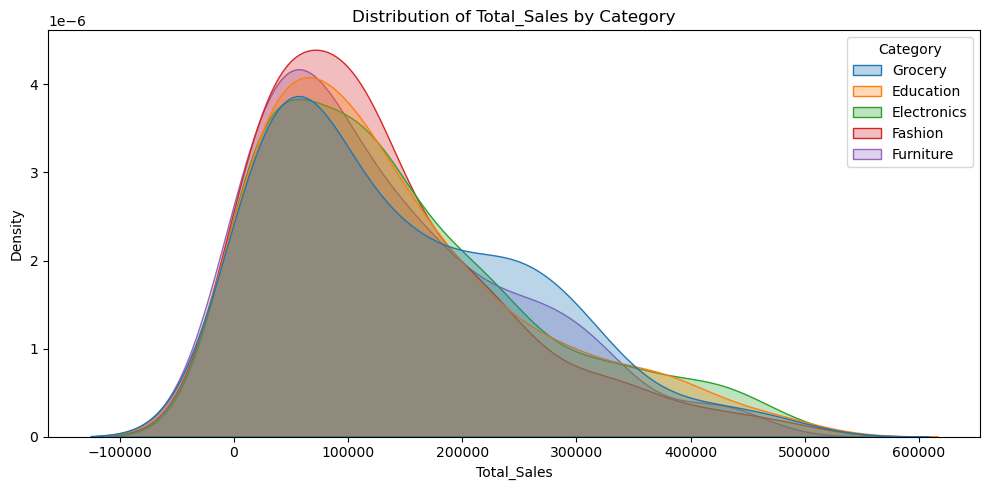

In [33]:
for num_col in numerical_cols:
    for cat_col in categorical_cols:

        plt.figure(figsize=(10, 5))

        sns.kdeplot(
            data=df,
            x=num_col,
            hue=cat_col,
            fill=True,
            common_norm=False,
            alpha=0.3
        )

        plt.title(f'Distribution of {num_col} by {cat_col}')
        plt.xlabel(num_col)
        plt.ylabel('Density')
        plt.tight_layout()
        plt.show()

## Multivariate Analysis

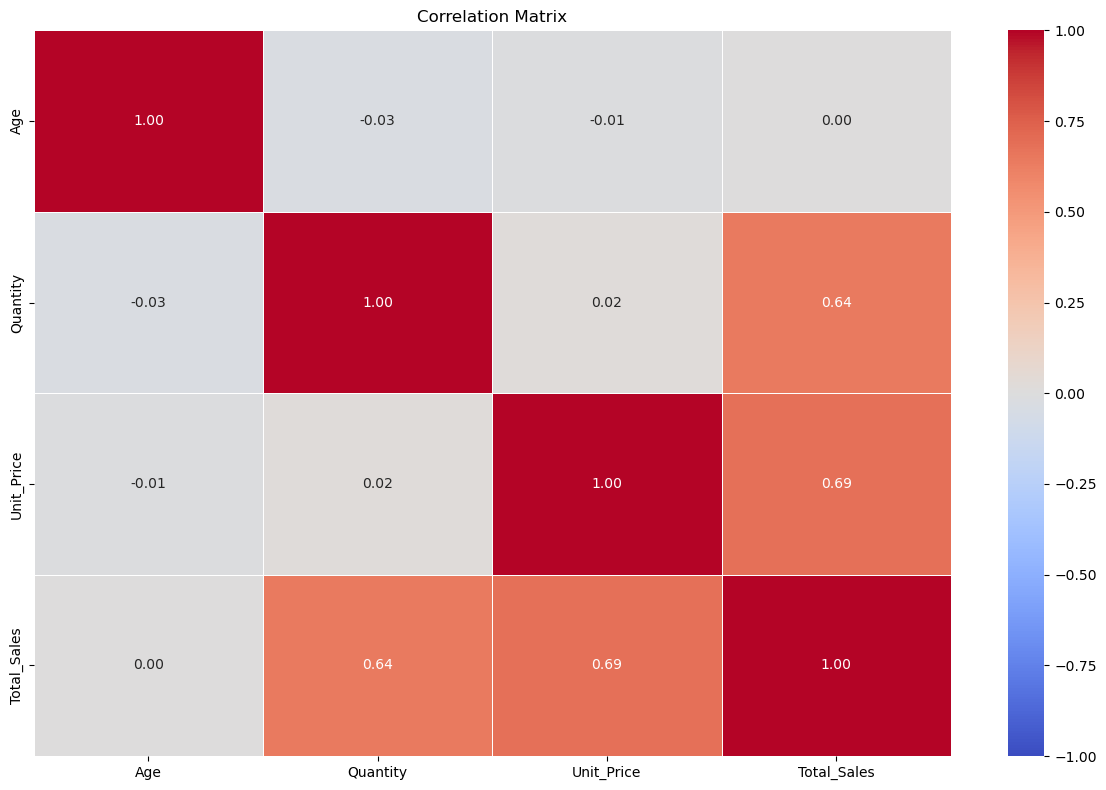

In [34]:
# Calculate correlation
corr_matrix = df[numerical_cols].corr()

# Plot heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()